# CODE to visualize significant genes/peak QTL counts across cells
Author: Gracie Gordon 2025

In [1]:
import genetics_plotting_utils as gu
import pandas as pd
import gwaslab as gl
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt

by .GlobalEnv when processing object ‘.pbd_env’


In [2]:
L2_colors = {
   'CD4T_Naive':   '#5A1C1C',  # deep brownish-maroon
   'CD4T_Memory':  '#752211',  # deep brick red (darker, less orange)
   'Treg':         '#C45F30',  # lighter burnt orange-brown (more rusty)
   'CD8T_Naive':   '#730000',  # wine red
   'CD8T_Memory':  '#C0392B',  # classic tomato red
   'gdT':          '#E1573A',  # warm coral red
   'MAIT':         '#FF8C42',  # vivid orange
   'NK_bright':    '#F48C06',  # golden orange
   'NK_dim':       '#D95F02',  # reddish orange
   'B_Memory': '#0B5F2F', 'B_Naive': '#2D9A57', 'B_atypical': '#40BD5C', 'Plasma': '#7FC685',
   'cDC1': '#16376A', 'cDC2': '#2B5CCD', 'pDC': '#4A85E3', 'cM': '#3E8599', 'ncM': '#65B0C4', 'Progen': '#595959', 'Prolif': '#9F7F66'
}

L1_colors = {
   "B": "#2D6A3F",
   "Plasma": "#7FB685",
   "CD4T": "#6B1C1C",
   "CD8T": "#A13030",
   "gdT": "#E3735E",
   "MAIT": "#FFA07A",
   "NK": "#F47024",
   "cDC": "#284F8C",
   "pDC": "#4A75D3",
   "cM": "#3E8589",
   "ncM": "#65B0B4",
   "Progen": "#595959",
   "Prolif": "#907F66"
 }


In [ ]:
def create_sig_counts_percell(df):
    import pandas as pd

    # Filter the data for significant rows
    filtered = df[df['pval_nominal'] < df['pval_nominal_threshold']]

    # Create a DataFrame of unique cell_type and phenotype_id pairs
    unique_pairs = filtered[['cell_type', 'phenotype_id']].drop_duplicates()

    # Perform a self-merge to find shared phenotype_id values between cell types
    merged = unique_pairs.merge(unique_pairs, on='phenotype_id')

    # Group by paired cell types and count shared phenotype_id values
    shared_counts = merged.groupby(['cell_type_x', 'cell_type_y']).size().reset_index(name='shared_counts')

    # Optionally, pivot the table for a matrix-like view
    shared_counts_pivot = shared_counts.pivot(index='cell_type_x', columns='cell_type_y', values='shared_counts').fillna(0)

    # Print the resulting table
    return(shared_counts_pivot)

def make_heatmap(df_pivot,title="Heatmap of eGenes Shared Between Cell Types"):
    # Convert the table values to numeric for heatmap
    heatmap_data = df_pivot.apply(pd.to_numeric)

    # Create the heatmap
    plt.figure(figsize=(10, 8))
    sns.heatmap(heatmap_data, annot=True, fmt="d", cmap="YlGnBu", cbar=True)

    # Add labels and title
    plt.title(title)
    plt.xlabel("cell type 2")
    plt.ylabel("cell type 1")

    # Show the plot
    plt.show()

def make_jaccard_df(df,cells):
    filtered = df[df['pval_nominal'] < df['pval_nominal_threshold']]
    unique_pairs = filtered[['cell_type', 'phenotype_id']].drop_duplicates()
    from itertools import combinations_with_replacement
    cell_combs=list(combinations_with_replacement(cells, 2))
    jaccard_df=pd.DataFrame(index=cells, columns=cells)
    for comb in cell_combs:
        #print(f"Cell type: {comb[0]} vs {comb[1]}")
        c1_genes=unique_pairs[unique_pairs['cell_type']==comb[0]]['phenotype_id']
        c2_genes=unique_pairs[unique_pairs['cell_type']==comb[1]]['phenotype_id']
        intersection=len(set(c1_genes).intersection(set(c2_genes)))

        union=len(set(c1_genes).union(set(c2_genes))) 
        jaccard_df.loc[comb[0],comb[1]]=intersection / union if union != 0 else 0
        jaccard_df.loc[comb[1],comb[0]]=intersection / union if union != 0 else 0
        #cell_df = merged[merged['cell_type_x'] == cell]
        #print(cell_df[['cell_type_y', 'phenotype_id']].drop_duplicates().shape[0], "shared eGenes with other cell types")
    return(jaccard_df)

def make_split_heatmap(df_pivot,title="Heatmap of eGenes Shared Between Cell Types",num_type='d'):
    # Convert the table values to numeric for heatmap
    heatmap_data = df_pivot.apply(pd.to_numeric)

    mask_upper = np.triu(np.ones(heatmap_data.shape), k=1).astype(bool)  # Exclude diagonal
    mask_lower = np.tril(np.ones(heatmap_data.shape), k=-1).astype(bool)  # Exclude diagonal

    # Create the heatmap
    fig, ax = plt.subplots(figsize=(8, 6))
    # Plot lower triangle with one color palette
    sns.heatmap(heatmap_data, mask=~mask_lower, cmap="Blues",fmt=num_type, ax=ax, cbar=False, annot=True)

    # Overlay upper triangle with another color palette
    sns.heatmap(heatmap_data, mask=~mask_upper, cmap="Reds",fmt=num_type, ax=ax, cbar=False, annot=True)

    # Add a color bar for clarity
    plt.colorbar(ax.collections[1], ax=ax, orientation='vertical', label='eGenes')
    plt.colorbar(ax.collections[0], ax=ax, orientation='vertical', label='aPeaks')


    # Add labels and title
    plt.title(title)
    plt.xlabel("cell type 2")
    plt.ylabel("cell type 1")

    # Show the plot
    plt.show()

def combine_egene_files( dir, cells, chr_start=1, chr_end=23):
    for cell in cells:

        print(cell)
        for i in range(chr_start,chr_end):
            if(i == chr_start and cell==cells[0]):
                egene=pd.read_csv(f"{dir}/{cell}/{cell}.cis_qtl_egene.{i}.txt", sep="\t")
                egene['cell_type']=cell
            else:
                tmp_egene=pd.read_csv(f"{dir}/{cell}/{cell}.cis_qtl_egene.{i}.txt", sep="\t")
                tmp_egene['cell_type']=cell
                egene=pd.concat([egene,tmp_egene], axis=0)

    return(egene)
    
def merge_hit_count_matrix(counts1, counts2,num_type=int):
    #merge two counts
    # Extract the lower triangle
    mask = np.tril(np.ones(counts1.shape)).astype(bool)
    lower_triangle =counts1.where(mask)
    mask = np.triu(np.ones(counts2.shape)).astype(bool)
    upper_triangle =counts2.where(mask)

    merged_matrix = lower_triangle.fillna(upper_triangle)
    for i in range(len(merged_matrix)):
        merged_matrix.iat[i, i] = 0 #np.nan

    merged_matrix = merged_matrix.astype(num_type)
    return(merged_matrix)

In [4]:
cells=['B','CD4T','CD8T','cDC','NK']
rna_egene=combine_egene_files("/gstore/data/ctgbioinfo/gordom14/ICC/data/QTL_calling/rna/L1_manual", cells,chr_start=5,chr_end=6)
atac_egene=combine_egene_files("/gstore/data/ctgbioinfo/gordom14/ICC/data/QTL_calling/atac/permissive/L1_manual", cells,chr_start=5,chr_end=6)

B
CD4T
CD8T
cDC
NK
B
CD4T
CD8T
cDC
NK


In [5]:
egene_counts=create_sig_counts_percell(rna_egene)
apeak_counts=create_sig_counts_percell(atac_egene)


In [86]:
rna_jaccard_df=make_jaccard_df(rna_egene,cells)
atac_jaccard_df=make_jaccard_df(atac_egene,cells)

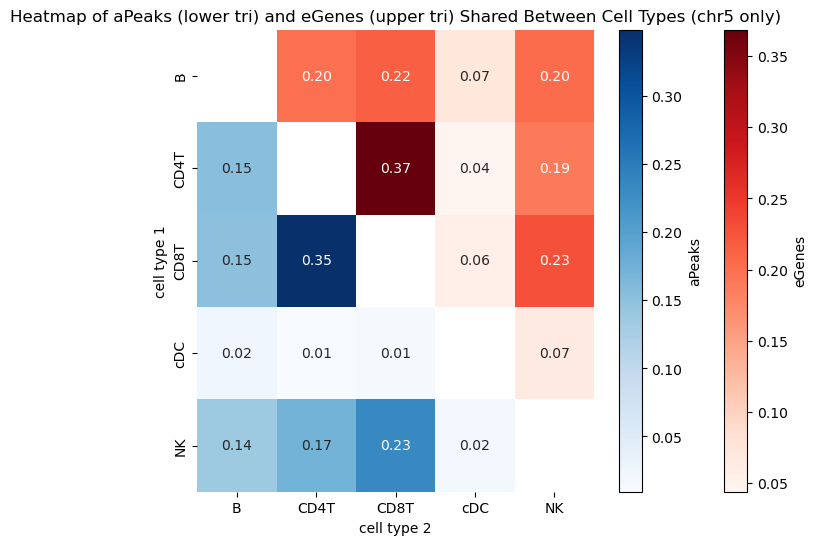

In [91]:
df_plot=merge_hit_count_matrix(atac_jaccard_df,rna_jaccard_df,float)
make_split_heatmap(df_plot,title="Heatmap of aPeaks (lower tri) and eGenes (upper tri) Shared Between Cell Types (chr5 only)",num_type='.2f')

In [80]:
atac_jaccard_df

,B,CD4T,CD8T,cDC,NK
B,1.0,0.154023,0.15237,0.021845,0.137417
CD4T,0.154023,1.0,0.348862,0.00939,0.172458
CD8T,0.15237,0.348862,1.0,0.013783,0.234043
cDC,0.021845,0.00939,0.013783,1.0,0.018634
NK,0.137417,0.172458,0.234043,0.018634,1.0


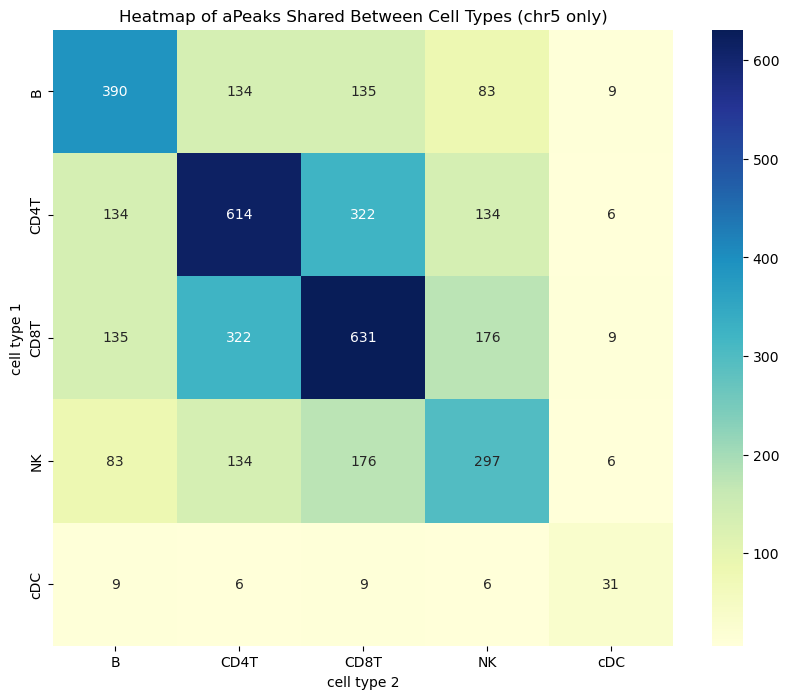

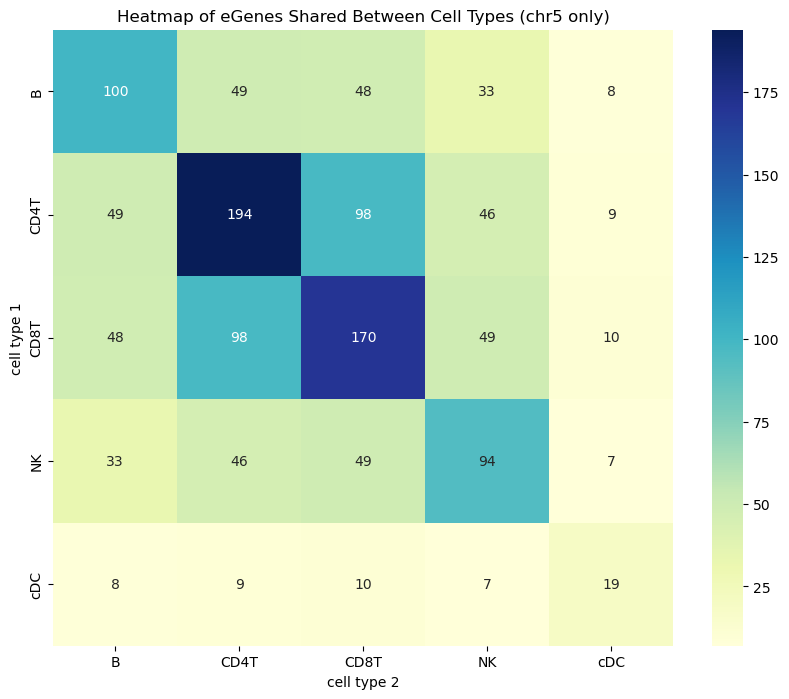

In [6]:
# just chr 5
make_heatmap(apeak_counts,title="Heatmap of aPeaks Shared Between Cell Types (chr5 only)")
make_heatmap(egene_counts,title="Heatmap of eGenes Shared Between Cell Types (chr5 only)")

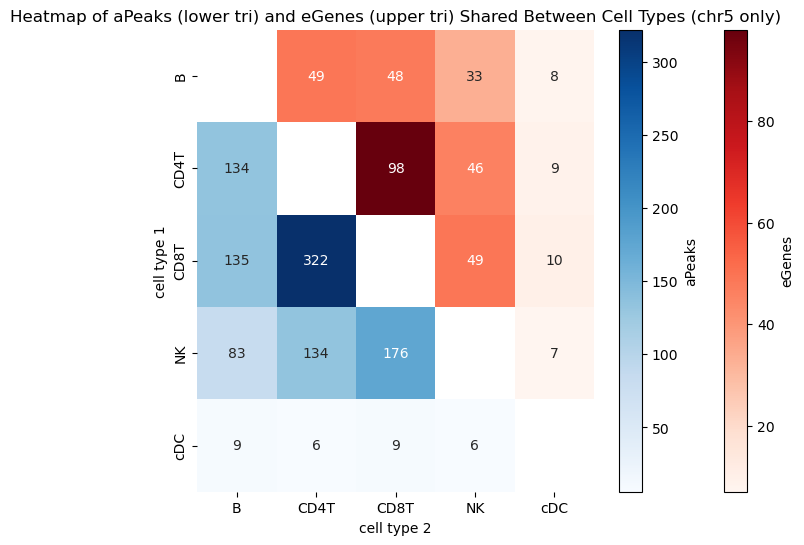

In [ ]:
df_plot=merge_hit_count_matrix(apeak_counts,egene_counts)
make_split_heatmap(df_plot,title="Heatmap of aPeaks (lower tri) and eGenes (upper tri) Shared Between Cell Types (chr5 only)")

# make per correlation eGene aPeak Plots

In [10]:
def count_sig_features(df,col_name='sig_count'):
    sig_df=pd.DataFrame(df[df['pval_nominal']<df['pval_nominal_threshold']][['cell_type','phenotype_id']].drop_duplicates()[['cell_type']].value_counts())
    sig_df.columns=[col_name]
    return(sig_df)

In [11]:
sig_peaks=count_sig_features(atac_egene,'aPeaks')
sig_genes=count_sig_features(rna_egene,'eGene')

merged_df = sig_peaks.merge(sig_genes, on='cell_type', how='outer')

In [12]:

# read in basic counts
donor_cell_counts=pd.read_csv('/gstore/data/ctgbioinfo/gordom14/ICC/data/QTL_calling/rna/L1_manual/donor_cell_counts_exp.txt',sep='\t')
donor_read_counts=pd.read_csv('/gstore/data/ctgbioinfo/gordom14/ICC/data/QTL_calling/rna/L1_manual/donor_counts_exp.txt',sep='\t')
cells=['B','CD4T','CD8T','cDC','NK']
cell_min=50
for cell in cells:
    n_donor=donor_cell_counts[donor_cell_counts[cell]>cell_min].shape[0]
    donors=donor_cell_counts[donor_cell_counts[cell]>cell_min]['Unnamed: 0'].unique()
    avg_cells=int(donor_cell_counts[donor_cell_counts[cell]>cell_min][cell].mean())
    avg_reads=int(donor_read_counts[donor_read_counts['best_sample'].isin(donors)][cell].mean())
    if(cell==cells[0]):
        donor_cell_df=pd.DataFrame({'cell_type':[cell],'n_donors':[n_donor],'avg_cells':[avg_cells], 'avg_reads':[avg_reads]})
    else:
        tmp_donor_cell_df=pd.DataFrame({'cell_type':[cell],'n_donors':[n_donor],'avg_cells':[avg_cells], 'avg_reads':[avg_reads]})
        donor_cell_df=pd.concat([donor_cell_df,tmp_donor_cell_df], axis=0)



In [13]:

merged_df = merged_df[merged_df.index!='cM'].merge(donor_cell_df, on='cell_type', how='outer') 
merged_df['avg_reads']=merged_df['avg_reads'].astype(int)

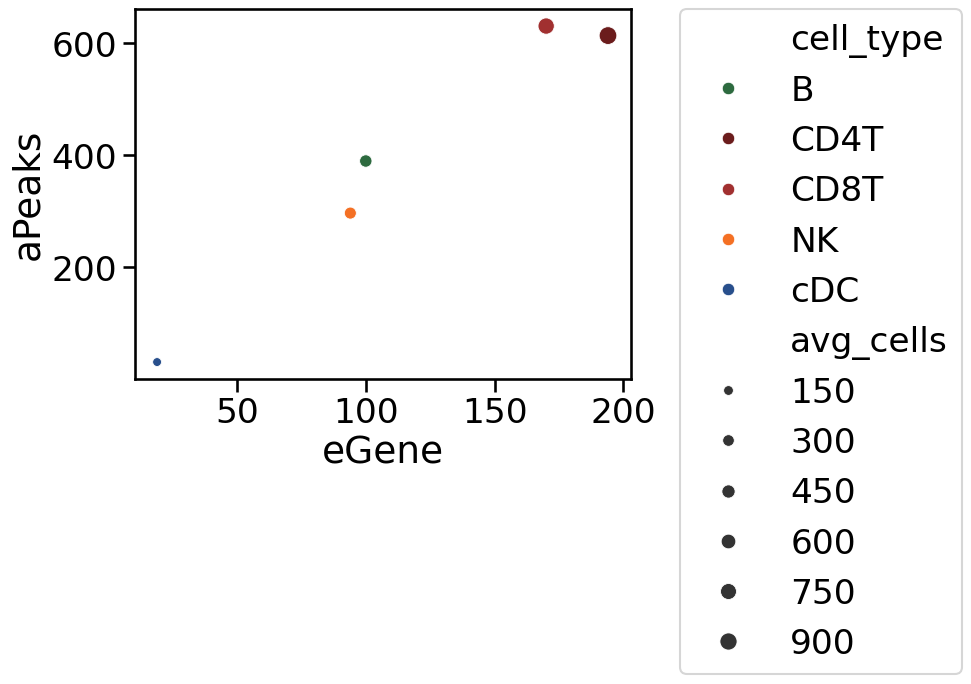

In [16]:
sns.set_context("talk", font_scale=1.5)  # "talk" increases text size, font_scale adjusts scaling

sns.scatterplot(data=merged_df, x='eGene', y='aPeaks',hue='cell_type',size='avg_cells',
                palette=L1_colors,legend="brief")#,sizes=(100, 400))
# Move the legend outside the plot
plt.legend(bbox_to_anchor=(1.1, 1), loc='upper left', borderaxespad=0)
